# RR breaking point and workload rates

This notebook estimates the request arrival rate where round-robin (RR) stops keeping up for each FairRoute workload. It inspects the pilot trace shapes, then measures the RR response in the existing experiment outputs. It prints a suggested `LAM_W1` … `LAM_W5` block for `scripts/build_fairroute_suite.sh`.

**Data source:** direct RR pilot result CSVs are read from `outputs/fairroute/pilot/<workload>/<pilot-cell>/trace_policy_RR.csv`. The notebook reports pilot cells whose request CSV is absent or incomplete, and does not mix main-suite aggregates into a direct-pilot curve. It falls back to the checked-in main-suite summary only when no direct pilot result exists at all.

The knee rule is deliberately simple and inspectable: choose the tested arrival rate immediately below the first clear queue-delay escalation, using both p99 queue delay and completion throughput. W4 is session-arrival rate; all other workloads use requests/s.


In [1]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "workloads/fairroute/pilot").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository or one of its subdirectories.")
PILOT_DIR = ROOT / "workloads/fairroute/pilot"
PILOT_RESULTS = ROOT / "outputs/fairroute/pilot_rr"
SUMMARY_CSV = ROOT / "notebooks/outputs/fairroute_full_summary.csv"


## Inspect pilot traces

In [2]:
def inspect_trace(path):
    requests, arrivals = [], []
    with path.open() as f:
        for line in f:
            if line.strip():
                row = json.loads(line)
                arrival = int(row["arrival_time_ns"])
                arrivals.append(arrival)
                for req in row.get("sub_requests", [row]):
                    requests.append((arrival, int(req["input_toks"]), int(req["output_toks"]), int(row["client_id"])))
    if not requests:
        return None
    a = np.asarray(requests, dtype=np.int64)
    span_s = max((a[:, 0].max() - a[:, 0].min()) / 1e9, 0)
    return {"workload": path.parent.parent.name, "cell": path.parent.name,
            "arrivals": len(arrivals), "requests": len(requests), "clients": len(np.unique(a[:, 3])),
            "duration_s": span_s, "input_tok_median": np.median(a[:, 1]),
            "input_tok_p95": np.percentile(a[:, 1], 95),
            "output_tok_median": np.median(a[:, 2]), "output_tok_p95": np.percentile(a[:, 2], 95),
            "observed_request_rate_rps": len(requests) / span_s if span_s else np.nan}

pilot_files = sorted(PILOT_DIR.glob("w*/r*_s*/trace.jsonl"))
if not pilot_files:
    raise FileNotFoundError(f"No pilot traces found below {PILOT_DIR}")
pilot = pd.DataFrame([x for f in pilot_files if (x := inspect_trace(f)) is not None])
display(pilot.sort_values(["workload", "cell"]).reset_index(drop=True))


,workload,cell,arrivals,requests,clients,duration_s,input_tok_median,input_tok_p95,output_tok_median,output_tok_p95,observed_request_rate_rps
0,w1,r16_s7,6124,6124,16,380.487158,40.0,5415.55,257.0,732.85,16.095156
1,w1,r2_s7,2527,2527,16,1238.482818,38.0,5296.50,253.0,754.70,2.040400
2,w1,r4_s7,2527,2527,16,619.241409,38.0,5296.50,253.0,754.70,4.080799
3,w1,r8_s7,3034,3034,16,371.394379,38.5,5142.80,263.5,695.35,8.169214
4,w2,r16_s7,6090,6090,8,380.587783,38.0,2391.75,276.0,772.00,16.001565
5,w2,r2_s7,2547,2547,8,1239.207177,39.0,2586.50,282.0,781.50,2.055346
6,w2,r4_s7,2547,2547,8,619.603589,39.0,2586.50,282.0,781.50,4.110693
7,w2,r8_s7,3047,3047,8,372.129352,39.0,2623.00,281.0,771.00,8.188013
8,w3,r16_s7,4800,4800,16,341.923315,678.0,4303.00,148.0,550.05,14.038235
9,w3,r2_s7,2000,2000,16,1145.246723,682.5,4305.05,145.0,565.15,1.746349


Pilot traces describe the offered load and request mix, including session traces whose top-level rows contain `sub_requests`. The next cell reads the direct RR request CSVs and shows coverage before analysing only completed pilot cells.

In [3]:
def read_request_csv(path, workload, rate):
    d = pd.read_csv(path)
    required = {"arrival", "end_time", "queuing_delay"}
    if d.empty or not required.issubset(d.columns):
        return None
    # Simulator request CSV times are nanoseconds; retain milliseconds for plots.
    for col in required | {"latency"}:
        if col in d:
            d[col] = pd.to_numeric(d[col], errors="coerce") / 1e6
    d = d.dropna(subset=list(required))
    if d.empty:
        return None
    d["workload"], d["rate_rps"], d["source"] = workload, rate, "pilot"
    return d

def pilot_rr_results():
    found, usable_cells = [], set()
    for p in sorted(PILOT_RESULTS.glob("w*/r*_s*/trace_policy_RR.csv")):
        match = re.fullmatch(r"(w[1-5])/r([0-9.]+)_s[0-9]+", str(p.parent.relative_to(PILOT_RESULTS)))
        if match:
            workload, rate = match.group(1), float(match.group(2))
            run = read_request_csv(p, workload, rate)
            if run is not None:
                found.append(run)
                usable_cells.add((workload, p.parent.name))
    return found, usable_cells

pilot_runs, usable_cells = pilot_rr_results()
expected_cells = set(map(tuple, pilot[["workload", "cell"]].to_numpy()))
missing_cells = sorted(expected_cells - usable_cells)
coverage = pd.DataFrame([{"workload": w, "cell": c,
                          "request_csv": "available" if (w, c) in usable_cells else "missing or incomplete"}
                         for w, c in sorted(expected_cells)])
display(coverage)
if missing_cells:
    print("Excluded incomplete pilot cells: " + ", ".join(f"{w}/{c}" for w, c in missing_cells))
if pilot_runs:
    rr_requests = pd.concat(pilot_runs, ignore_index=True)
    print(f"Using {len(pilot_runs)} direct RR pilot cells.")
else:
    if not SUMMARY_CSV.exists():
        raise FileNotFoundError(f"Neither usable pilot RR CSVs nor {SUMMARY_CSV} were found")
    summary = pd.read_csv(SUMMARY_CSV)
    rr_summary = summary.loc[summary.policy_name.eq("RR")].copy()
    rr_summary["rate_rps"] = rr_summary.apply(lambda r: float(r["rho"]) * {"w1": 2, "w2": 2, "w3": 2, "w4": .5, "w5": 4}[r["workload"]], axis=1)
    print("No usable direct RR pilot CSVs found; using existing main-suite RR aggregate rows.")


,workload,cell,request_csv
0,w1,r16_s7,available
1,w1,r2_s7,available
2,w1,r4_s7,available
3,w1,r8_s7,available
4,w2,r16_s7,available
5,w2,r2_s7,available
6,w2,r4_s7,available
7,w2,r8_s7,available
8,w3,r16_s7,available
9,w3,r2_s7,available


Using 20 direct RR pilot cells.


## Find the RR knee

,workload,rate_rps,queue_p50_ms,queue_p99_ms,throughput_rps,makespan_inflation,source
0,w1,2.0,16.98,306.36,2.03,1.01,pilot
1,w1,4.0,18.01,307.96,3.98,1.03,pilot
2,w1,8.0,204.31,5910.16,7.53,1.10,pilot
3,w1,16.0,21626.74,51429.13,8.34,1.97,pilot
4,w2,2.0,16.93,302.70,2.04,1.02,pilot
5,w2,4.0,18.04,878.25,3.89,1.07,pilot
6,w2,8.0,4315.29,19743.22,6.37,1.27,pilot
7,w2,16.0,36810.99,86046.33,6.03,2.75,pilot
8,w3,2.0,13.49,23.31,1.92,1.01,pilot
9,w3,4.0,17.05,23.59,3.77,1.03,pilot


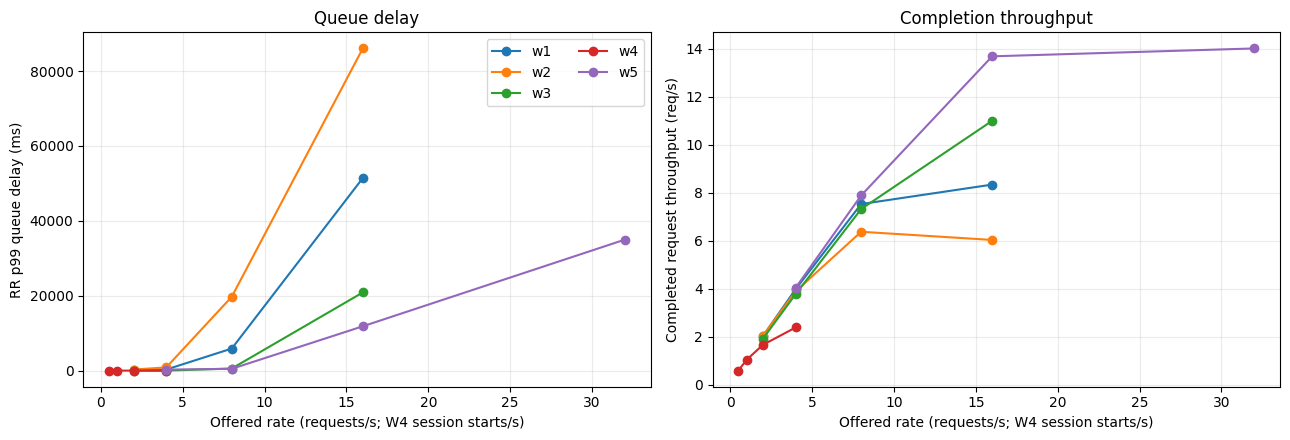

In [4]:
if pilot_runs:
    records = []
    for (w, rate), d in rr_requests.groupby(["workload", "rate_rps"]):
        # Timestamps were converted to milliseconds above; divide once to obtain seconds.
        span = (d["end_time"].max() - d["arrival"].min()) / 1000
        arrival_span = (d["arrival"].max() - d["arrival"].min()) / 1000
        records.append({"workload": w, "rate_rps": rate, "queue_p99_ms": d["queuing_delay"].quantile(.99),
                        "queue_p50_ms": d["queuing_delay"].median(),
                        "throughput_rps": len(d) / span if pd.notna(span) and span > 0 else np.nan,
                        "makespan_inflation": span / arrival_span if pd.notna(span) and arrival_span > 0 else np.nan,
                        "source": "pilot"})
    curve = pd.DataFrame(records)
else:
    curve = rr_summary.rename(columns={"queue_delay_p99_ms":"queue_p99_ms", "request_throughput":"throughput_rps"})
    curve["source"] = "existing main RR summary"
    # Map W4's aggregate request completion rate back to session start-rate scale for plotting only.

curve = curve.sort_values(["workload", "rate_rps"]).reset_index(drop=True)
show = [c for c in ["workload", "rate_rps", "queue_p50_ms", "queue_p99_ms", "throughput_rps", "makespan_inflation", "source"] if c in curve]
display(curve[show].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for w, d in curve.groupby("workload"):
    axes[0].plot(d.rate_rps, d.queue_p99_ms, marker="o", label=w)
    axes[1].plot(d.rate_rps, d.throughput_rps, marker="o", label=w)
axes[0].set(xlabel="Offered rate (requests/s; W4 session starts/s)", ylabel="RR p99 queue delay (ms)", title="Queue delay")
axes[1].set(xlabel="Offered rate (requests/s; W4 session starts/s)", ylabel="Completed request throughput (req/s)", title="Completion throughput")
for ax in axes: ax.grid(alpha=.25)
axes[0].legend(ncol=2)
plt.tight_layout()


## Recommended `LAM_*` values

For each workload, select the largest tested rate before a queue-delay knee. A knee is flagged when p99 queue delay rises to at least 2× the preceding point or exceeds 1 second; throughput is shown alongside it to distinguish rising latency under saturation from a rate that the system continues to absorb. If no knee appears in the measured range, the function selects the highest tested rate and flags it as a lower bound on capacity.

In [5]:
def choose_lam(d):
    d = d.sort_values("rate_rps").reset_index(drop=True)
    if len(d) < 2:
        return float(d.rate_rps.iloc[0]), "only one measured rate"
    base = max(float(d.queue_p99_ms.iloc[0]), 1.0)
    knee_idx = None
    for i in range(1, len(d)):
        prev, cur = float(d.queue_p99_ms.iloc[i-1]), float(d.queue_p99_ms.iloc[i])
        if cur >= 2 * max(prev, base) or cur >= 1000:
            knee_idx = i
            break
    if knee_idx is None:
        return float(d.rate_rps.iloc[-1]), "no knee observed; capacity is at least this rate"
    return float(d.rate_rps.iloc[knee_idx-1]), f"below queue-delay knee at {d.rate_rps.iloc[knee_idx]:g}"

recommendations = {}
for w, d in curve.groupby("workload"):
    recommendations[w] = choose_lam(d)
rec = pd.DataFrame([{"workload":w, "LAM_rate":rate, "selection":why} for w,(rate,why) in recommendations.items()])
display(rec)
print("\n# Add to your shell before generating main/scaling workloads:")
for w in sorted(recommendations):
    print(f"export LAM_{w.upper()}={recommendations[w][0]:g}")


,workload,LAM_rate,selection
0,w1,4.0,below queue-delay knee at 8
1,w2,2.0,below queue-delay knee at 4
2,w3,4.0,below queue-delay knee at 8
3,w4,4.0,no knee observed; capacity is at least this rate
4,w5,8.0,below queue-delay knee at 16



# Add to your shell before generating main/scaling workloads:
export LAM_W1=4
export LAM_W2=2
export LAM_W3=4
export LAM_W4=4
export LAM_W5=8


## What makes the generated suite useful

Keep the workload mix fixed while sweeping the offered rate around each `LAM` (the generator’s default `LEVELS` are 0.5, 0.8, 1.0, 1.25, and 1.5). Use multiple seeds for the main comparison and retain the 7-seed tune split only for parameter tuning. W1/W3 scaling workloads vary client count separately from load. After direct pilot RR runs are available, rerun this notebook and update `EXPERIMENTS.md` if the selected rates change. The current documented values are 2, 2, 2, 0.5, and 4 respectively; the checked-in main-suite curves make these reasonable working estimates but do not substitute for direct pilot RR measurements.